# EA3 · Observaciones climáticas de Medellín y Puebla — 2026
**Silvia Rosa Posso Mazo** · Consulta de fuentes: 10 de noviembre de 2026.

## A. Pregunta y expectativa inicial
**Pregunta guía:** ¿cómo se diferencian la temperatura mínima diaria y la precipitación de las estaciones seleccionadas de Medellín y Puebla durante enero–octubre de 2026?

**Predicción, antes de calcular las estadísticas:** espero que Medellín tenga mínimas diarias más altas y menos variables que Puebla, y que ambas estaciones presenten días lluviosos y cambios mensuales de precipitación. Es una expectativa que se contrasta con los datos, no una conclusión anticipada. Se utilizarán los mismos umbrales en ambas ciudades: día lluvioso si la precipitación es mayor que 0 mm y mínima elevada si supera 15 °C. Una mínima mayor que 15 °C no significa necesariamente un día caluroso.

## 1. Fuentes, periodo y alcance
Se utilizan **observaciones de estaciones**, descargadas del IDEAM (Colombia) y de CONAGUA/Servicio Meteorológico Nacional (México). No se emplean pronósticos ni datos inventados.

**Periodo común fijado para ambas ciudades: 1 de enero a 31 de octubre de 2026, ambos inclusive; frecuencia diaria; 304 fechas.** Se usan los meses terminados del año solicitado. No corresponde a un año calendario completo: 2026 todavía está en curso. No se utiliza una intersección de fechas ni se recorta una ciudad para ajustarla a la otra.

**Cobertura verificada:** ambas ciudades tienen **304 temperaturas mínimas y 304 precipitaciones**, sin duplicados ni valores ausentes en las variables seleccionadas. Se utiliza temperatura mínima porque la máxima de LA ALDEA tiene dos huecos en 2026. La actividad permite escoger una variable de temperatura comparable: se compara **mínima con mínima**, en °C. No se mezclan máximas con mínimas ni se completan observaciones artificialmente.

**Calidad:** las observaciones de IDEAM figuran En revisión o Preliminar. Tener todas las fechas no significa que la entidad haya finalizado su validación. El TXT de CONAGUA no publica un nivel de aprobación individual.

| Característica | Medellín, Colombia | Puebla, México |
|---|---|---|
| Fuente | IDEAM, portal DHIME | CONAGUA/SMN, Base de Datos Climatológica Nacional |
| Estación | LA ALDEA, 26205080 | PUEBLA (OBS), 21065, municipio Puebla |
| Ubicación | 6.34105556 N, −75.70094444; 1737 m, según catálogo IDEAM | 19.05 N, −98.16666667; 2179 m, según cabecera del registro |
| Archivo original descargado | `datos/ideam_aldea_2026_TMN_CON.zip` | `datos/mexico_21065_diarios.txt` |
| Columnas originales utilizadas | CodigoEstacion, NombreEstacion, Variable, Parametro, Fecha, Unidad, Valor, NivelAprobacion | FECHA, PRECIP, TMIN; EVAP y TMAX no se utilizan |
| Temperatura | Temperatura mínima diaria (`TMN_CON`), degC | TMIN, °C |
| Precipitación | Día pluviométrico convencional (`PTPM_CON`), mm | PRECIP, mm |
| Frecuencia utilizada | Diaria | Diaria |
| Periodo utilizado | 2026-01-01 a 2026-10-31 | 2026-01-01 a 2026-10-31 |
| Unidades de salida | °C y mm | °C y mm |
| Estado de validación | Se conserva NivelAprobacion: En revisión y Preliminar | El TXT no ofrece una bandera de aprobación por observación; no se le atribuye validación que no declare |

### Enlaces y trazabilidad
- IDEAM: [portal público de consulta](https://atencionciudadano.ideam.gov.co/). La descarga se obtuvo del servicio usado por ese portal, no de un enlace supuesto. La **consulta exacta sin credenciales** se conserva en `datos/ideam_aldea_2026_TMN_CON.zip.consulta.json` y se imprime más adelante.
- IDEAM: [catálogo de series de LA ALDEA](https://dhime.ideam.gov.co/server/rest/services/CNE/Estaciones/MapServer/8/query?f=json&where=idestacion%3D%2726205080%27&outFields=*&returnGeometry=false). Confirma municipio Medellín y las descripciones de las dos variables. Copia local: `datos/dhime_aldea.json`.
- CONAGUA: [registro diario histórico de Puebla, estación 21065](https://smn.conagua.gob.mx/tools/RESOURCES/Normales_Climatologicas/Diarios/pue/dia21065.txt). Es el archivo descargado y leído, con cabecera REGISTRO DIARIO HISTÓRICO, unidades y coordenadas.
- CONAGUA: [catálogo del mapa oficial](https://smn.conagua.gob.mx/tools/GUI/estaciones-climatologicas/data/estaciones_climatologicas.geojson). Su propiedad `diarios` contiene el enlace anterior; se guarda una ficha de la estación en `datos/fuentes_estaciones.json`.

Las tablas finales pueden leerse sin conexión a internet. El servicio de DHIME puede cambiar; el script `descargar_ideam.ps1` documenta cómo se obtuvo la descarga mediante el acceso público del portal. No se guardan tokens.

In [1]:
from pathlib import Path
from datetime import date, timedelta
from collections import Counter
import csv, hashlib, json, math, re, statistics, zipfile

BASE = Path.cwd()
if (BASE / 'EA3_comparacion_climatica').is_dir():
    BASE = BASE / 'EA3_comparacion_climatica'
DATOS = BASE / 'datos'
INICIO, FIN = date(2026, 1, 1), date(2026, 10, 31)
FECHAS = [(INICIO + timedelta(days=n)).isoformat()
          for n in range((FIN - INICIO).days + 1)]
assert len(FECHAS) == 304
print(f'Periodo común: {INICIO} a {FIN}; {len(FECHAS)} días; frecuencia diaria.')

Periodo común: 2026-01-01 a 2026-10-31; 304 días; frecuencia diaria.


In [2]:
# IDEAM: se lee el CSV dentro del ZIP original, sin modificarlo.
with zipfile.ZipFile(DATOS / 'ideam_aldea_2026_TMN_CON.zip') as archivo:
    nombres = [n for n in archivo.namelist() if n.lower().endswith('.csv')]
    assert len(nombres) == 1
    crudo_ideam = list(csv.DictReader(
        archivo.read(nombres[0]).decode('utf-8-sig').splitlines()))

parametros = {
    'Temperatura mínima diaria': ('tmin_c', 'degC'),
    'Día pluviométrico (convencional)': ('precipitacion_mm', 'mm'),
}
medellin = {f: {'fecha': f, 'ciudad': 'Medellín', 'pais': 'Colombia',
               'estacion': '26205080', 'tmin_c': None, 'precipitacion_mm': None,
               'estado_tmin': 'Sin observación', 'estado_precipitacion': 'Sin observación'}
            for f in FECHAS}
vistas = set()
for r in crudo_ideam:
    assert r['CodigoEstacion'] == '26205080'
    assert r['Parametro'] in parametros
    columna, unidad = parametros[r['Parametro']]
    assert r['Unidad'] == unidad, f'Unidad inesperada: {r}'
    fecha = r['Fecha'][:10]
    assert fecha in medellin, f'Fecha fuera de la consulta fijada: {fecha}'
    clave = (fecha, columna)
    assert clave not in vistas, f'Observación duplicada: {clave}'
    vistas.add(clave)
    valor = float(r['Valor'])
    assert math.isfinite(valor)
    medellin[fecha][columna] = valor
    estado = 'estado_tmin' if columna == 'tmin_c' else 'estado_precipitacion'
    medellin[fecha][estado] = r['NivelAprobacion']

print('IDEAM: filas originales:', len(crudo_ideam))
print('Parámetros, unidades y estados:', dict(Counter(
    (r['Parametro'], r['Unidad'], r['NivelAprobacion']) for r in crudo_ideam)))
print('Conversión: degC y °C designan la misma unidad; no se modifica el valor.')

IDEAM: filas originales: 608
Parámetros, unidades y estados: {('Temperatura mínima diaria', 'degC', 'En revisión'): 242, ('Temperatura mínima diaria', 'degC', 'Preliminar'): 62, ('Día pluviométrico (convencional)', 'mm', 'En revisión'): 242, ('Día pluviométrico (convencional)', 'mm', 'Preliminar'): 62}
Conversión: degC y °C designan la misma unidad; no se modifica el valor.


In [3]:
# CONAGUA: se conserva el TXT histórico completo y se selecciona el MISMO periodo.
texto_mx = (DATOS / 'mexico_21065_diarios.txt').read_text(encoding='utf-8-sig')
assert 'REGISTRO DIARIO HISTÓRICO' in texto_mx
assert re.search(r'ESTACIÓN\s*:\s*21065', texto_mx)
assert 'PUEBLA (OBS)' in texto_mx

def numero_o_ausente(texto):
    if texto.strip() in {'', 'NULO'}:
        return None
    valor = float(texto)
    assert math.isfinite(valor)
    return valor

puebla = {}
for linea in texto_mx.splitlines():
    if not re.match(r'^\d{4}-\d{2}-\d{2}\t', linea):
        continue
    partes = linea.split('\t')  # conserva columnas vacías: no desplazar TMIN
    fecha = partes[0]
    if not INICIO.isoformat() <= fecha <= FIN.isoformat():
        continue
    assert len(partes) == 5, f'Estructura inesperada: {linea}'
    assert fecha not in puebla, f'Fecha duplicada: {fecha}'
    puebla[fecha] = {'fecha': fecha, 'ciudad': 'Puebla', 'pais': 'México',
        'estacion': '21065', 'tmin_c': numero_o_ausente(partes[4]),
        'precipitacion_mm': numero_o_ausente(partes[1]),
        'estado_tmin': 'No informado en el TXT',
        'estado_precipitacion': 'No informado en el TXT'}

print('Puebla:', len(puebla), 'fechas observadas en el periodo fijado.')
print('Columnas: FECHA → fecha; TMIN → tmin_c; PRECIP → precipitacion_mm.')
print('Unidades originales: TMIN en °C; PRECIP en mm. No requieren conversión.')
print('Las cantidades 0.01 mm se conservan exactamente como las publica la fuente.')

Puebla: 304 fechas observadas en el periodo fijado.
Columnas: FECHA → fecha; TMIN → tmin_c; PRECIP → precipitacion_mm.
Unidades originales: TMIN en °C; PRECIP en mm. No requieren conversión.
Las cantidades 0.01 mm se conservan exactamente como las publica la fuente.


## 3. Verificación del calendario y de la calidad
Se comprueban el rango, la frecuencia, los duplicados, las unidades y los valores ausentes. Crear una fila de calendario con una celda vacía **no crea una observación**: permite mostrar el hueco sin borrar fechas. En los CSV finales, una celda vacía representa ausencia, mientras que `0.0` de lluvia es una observación de precipitación cero.

Los valores negativos de precipitación no se aceptan. La comprobación de rango térmico es únicamente un control de plausibilidad, no una certificación de calidad del IDEAM o CONAGUA. Se conservan las fechas asignadas por cada organismo; no se desplazan para alinear valores. Los archivos no acreditan que los horarios exactos de cierre de los periodos de 24 horas sean idénticos entre las dos redes.

In [4]:
assert sorted(medellin) == sorted(puebla) == FECHAS
assert min(medellin) == min(puebla) == INICIO.isoformat()
assert max(medellin) == max(puebla) == FIN.isoformat()
tablas = {'Medellín': list(medellin.values()), 'Puebla': [puebla[f] for f in FECHAS]}
auditoria = []
for ciudad, filas in tablas.items():
    assert len({r['fecha'] for r in filas}) == 304
    for variable in ['tmin_c', 'precipitacion_mm']:
        faltantes = [r['fecha'] for r in filas if r[variable] is None]
        validos = [r[variable] for r in filas if r[variable] is not None]
        if variable == 'precipitacion_mm':
            assert all(v >= 0 for v in validos)
        else:
            assert all(-30 <= v <= 55 for v in validos)
        auditoria.append({'ciudad': ciudad, 'variable': variable,
            'dias_calendario': len(filas), 'observaciones': len(validos),
            'ausentes': len(faltantes), 'fechas_ausentes': faltantes})
        print(f'{ciudad:9} {variable:18} {len(validos):3}/304 observaciones; '
              f'ausentes: {faltantes or "ninguno"}')

assert all(r['tmin_c'] is not None for r in tablas['Medellín'])
assert all(r['precipitacion_mm'] is not None for r in tablas['Medellín'])
assert all(r['tmin_c'] is not None and r['precipitacion_mm'] is not None
           for r in tablas['Puebla'])
print('Calendarios y extremos iguales; 304 días completos en ambas ciudades; sin duplicados ni imputaciones.')

Medellín  tmin_c             304/304 observaciones; ausentes: ninguno
Medellín  precipitacion_mm   304/304 observaciones; ausentes: ninguno
Puebla    tmin_c             304/304 observaciones; ausentes: ninguno
Puebla    precipitacion_mm   304/304 observaciones; ausentes: ninguno
Calendarios y extremos iguales; 304 días completos en ambas ciudades; sin duplicados ni imputaciones.


In [5]:
# Exportación reproducible: ambas tablas conservan todas las fechas del periodo.
for ciudad, filas in tablas.items():
    nombre = 'medellin_2026_diario.csv' if ciudad == 'Medellín' else 'puebla_2026_diario.csv'
    with (DATOS / nombre).open('w', encoding='utf-8', newline='') as archivo:
        escritor = csv.DictWriter(archivo, fieldnames=list(filas[0]))
        escritor.writeheader()
        escritor.writerows(filas)
    print(nombre, '—', len(filas), 'filas')
    for r in filas[:3]:
        print(r['fecha'], 'Tmin:', r['tmin_c'], '°C; precipitación:', r['precipitacion_mm'], 'mm')

consulta = json.loads((DATOS / 'ideam_aldea_2026_TMN_CON.zip.consulta.json').read_text(encoding='utf-8-sig'))
fuentes = {
    'Medellín': consulta['url'],
    'Puebla': 'https://smn.conagua.gob.mx/tools/RESOURCES/Normales_Climatologicas/Diarios/pue/dia21065.txt',
}
archivos = ['ideam_aldea_2026_TMN_CON.zip', 'mexico_21065_diarios.txt',
            'medellin_2026_diario.csv', 'puebla_2026_diario.csv']
informe = {'consulta': '2026-11-10', 'inicio': INICIO.isoformat(), 'fin': FIN.isoformat(),
    'frecuencia': 'diaria', 'unidades': {'tmin_c': '°C', 'precipitacion_mm': 'mm'},
    'conversiones': 'Sin conversión numérica; degC se rotula °C.',
    'fuentes': fuentes, 'auditoria': auditoria,
    'series_temperatura_completas': True,
    'sha256': {n: hashlib.sha256((DATOS/n).read_bytes()).hexdigest() for n in archivos}}
(DATOS / 'verificacion_2026.json').write_text(
    json.dumps(informe, ensure_ascii=False, indent=2), encoding='utf-8')
print('Enlace exacto de la consulta IDEAM:', fuentes['Medellín'])
print('Informe de verificación y huellas SHA-256 guardados en verificacion_2026.json.')

medellin_2026_diario.csv — 304 filas
2026-01-01 Tmin: 17.4 °C; precipitación: 1.5 mm
2026-01-02 Tmin: 17.2 °C; precipitación: 7.5 mm
2026-01-03 Tmin: 16.6 °C; precipitación: 11.0 mm
puebla_2026_diario.csv — 304 filas
2026-01-01 Tmin: 4.2 °C; precipitación: 0.0 mm
2026-01-02 Tmin: 5.2 °C; precipitación: 0.0 mm
2026-01-03 Tmin: 6.0 °C; precipitación: 0.0 mm
Enlace exacto de la consulta IDEAM: https://modulopersonalizado.ideam.gov.co/DhimeServicePortal/api/Listas/ConsultarListaSeriesTiempoEstacionesPorFiltroString?mostrarGrado=true&filter=((IdParametro~eq~'TEMPERATURA'~and~Etiqueta~eq~'TMN_CON'~and~IdEstacion~eq~'26205080')~or~(IdParametro~eq~'PRECIPITACION'~and~Etiqueta~eq~'PTPM_CON'~and~IdEstacion~eq~'26205080'))&fechaInicio=2026-01-01T05%3A00%3A00.000Z&tipoReporte=csv&mostrarNivelAprobacion=true&fechaFin=2026-10-31T05%3A00%3A00.000Z&group=&mostrarCalificador=true&sort=
Informe de verificación y huellas SHA-256 guardados en verificacion_2026.json.


## 4. Uso correcto en la comparación posterior
Las dos tablas tienen el mismo calendario de 304 días. La temperatura mínima y la precipitación pueden compararse en las mismas 304 fechas, con iguales unidades y sin excluir días por faltantes. El periodo es idéntico para ambas ciudades; no se calculó mediante una unión interna que eliminara fechas.

LA ALDEA representa una estación dentro del municipio de Medellín, no un promedio del centro urbano. Puebla se representa con su observatorio. Las diferencias de altitud, entorno y horario de observación limitan la interpretación; el análisis describe estas estaciones en 2026 y no demuestra por sí solo un cambio climático.

**Resultado de la búsqueda:** archivos reales descargados, unidades y calendario verificados, dos tablas diarias de 2026 guardadas con 304 observaciones de temperatura mínima y 304 de precipitación cada una, sin faltantes. Las condiciones de calendario, frecuencia y variables comparables se cumplen para el periodo indicado; no se afirma que 2026 sea un año terminado.

## B. Carga de las dos tablas y tipos para el análisis
Las tablas finales se leen de `datos/`. Se convierten las fechas a `datetime64[D]` y las mediciones a `float64`. Se muestran dimensiones, columnas, primeras filas, extremos del periodo, duplicados y faltantes. Si aparecieran faltantes se conservarían como `NaN`, nunca como ceros. Las máscaras de validez deben aplicarse a ambas ciudades para cada variable.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

def tabla_html(encabezados, filas):
    from html import escape
    cab = ''.join('<th>' + escape(str(x)) + '</th>' for x in encabezados)
    cuerpo = ''.join('<tr>' + ''.join('<td>' + escape(str(x)) + '</td>' for x in fila)
                     + '</tr>' for fila in filas)
    display(HTML('<table><thead><tr>' + cab + '</tr></thead><tbody>' + cuerpo + '</tbody></table>'))

ciudades = ['Medellín', 'Puebla']
cargadas = []
for nombre in ['medellin_2026_diario.csv', 'puebla_2026_diario.csv']:
    with (DATOS / nombre).open(encoding='utf-8', newline='') as archivo:
        filas = list(csv.DictReader(archivo))
    cargadas.append(filas)
    f = np.array([r['fecha'] for r in filas], dtype='datetime64[D]')
    valores = np.array([[float(r[k]) if r[k] else np.nan
                        for k in ['tmin_c', 'precipitacion_mm']] for r in filas], dtype=np.float64)
    print(nombre, 'dimensiones:', (len(filas), len(filas[0])), 'columnas:', list(filas[0]))
    print('Tipos:', f.dtype, valores.dtype, 'fechas:', f.min(), 'a', f.max())
    print('Duplicados:', len(f) - len(np.unique(f)),
          'faltantes [temperatura, precipitación]:', np.isnan(valores).sum(axis=0))
    tabla_html(['Fecha', 'Mínima (°C)', 'Precipitación (mm)'],
               [[r['fecha'], r['tmin_c'], r['precipitacion_mm']] for r in filas[:5]])

fechas = np.array([r['fecha'] for r in cargadas[0]], dtype='datetime64[D]')
fechas_puebla = np.array([r['fecha'] for r in cargadas[1]], dtype='datetime64[D]')
assert np.array_equal(fechas, fechas_puebla)
assert np.all(np.diff(fechas) == np.timedelta64(1, 'D'))
# Filas = días; columnas = Medellín, Puebla.
temperatura = np.array([[float(rs[i]['tmin_c']) if rs[i]['tmin_c'] else np.nan
                         for rs in cargadas] for i in range(len(fechas))])
lluvia = np.array([[float(rs[i]['precipitacion_mm']) if rs[i]['precipitacion_mm'] else np.nan
                    for rs in cargadas] for i in range(len(fechas))])
validas_t = np.isfinite(temperatura).all(axis=1)
validas_p = np.isfinite(lluvia).all(axis=1)
validas_ambas = validas_t & validas_p
print('Disponibles para comparar: temperatura', validas_t.sum(),
      '; precipitación', validas_p.sum(), '; ambas', validas_ambas.sum())
assert validas_ambas.sum() == 304

medellin_2026_diario.csv dimensiones: (304, 8) columnas: ['fecha', 'ciudad', 'pais', 'estacion', 'tmin_c', 'precipitacion_mm', 'estado_tmin', 'estado_precipitacion']
Tipos: datetime64[D] float64 fechas: 2026-01-01 a 2026-10-31
Duplicados: 0 faltantes [temperatura, precipitación]: [0 0]


Fecha,Mínima (°C),Precipitación (mm)
2026-01-01,17.4,1.5
2026-01-02,17.2,7.5
2026-01-03,16.6,11.0
2026-01-04,15.6,12.4
2026-01-05,15.4,17.2


puebla_2026_diario.csv dimensiones: (304, 8) columnas: ['fecha', 'ciudad', 'pais', 'estacion', 'tmin_c', 'precipitacion_mm', 'estado_tmin', 'estado_precipitacion']
Tipos: datetime64[D] float64 fechas: 2026-01-01 a 2026-10-31
Duplicados: 0 faltantes [temperatura, precipitación]: [0 0]


Fecha,Mínima (°C),Precipitación (mm)
2026-01-01,4.2,0.0
2026-01-02,5.2,0.0
2026-01-03,6.0,0.0
2026-01-04,5.8,0.0
2026-01-05,5.2,0.0


Disponibles para comparar: temperatura 304 ; precipitación 304 ; ambas 304


## C. Análisis con NumPy: cortes, máscaras y broadcasting
Se inspeccionan los primeros siete días de ambas matrices. Las máscaras identifican lluvia observada (> 0 mm) y mínimas elevadas (> 15 °C); los umbrales son iguales para ambas ciudades. También se cuentan días con al menos 1 mm para distinguir lluvia apreciable de cantidades muy pequeñas.

El **broadcasting** permite restar el vector de promedios de las dos ciudades, de forma `(2,)`, a la matriz de temperaturas, de forma `(304, 2)`. Así se obtiene cuánto se aparta cada mínima del promedio de su propia estación, sin escribir un ciclo por día.

In [7]:
print('Corte [0:7] — fechas:', fechas[:7])
print('Temperatura mínima (°C), columnas Medellín/Puebla:\n', temperatura[:7, :])
print('Lluvia (mm), columnas Medellín/Puebla:\n', lluvia[:7, :])
UMBRAL_T = 15.0
lluviosos = (lluvia > 0.0) & np.isfinite(lluvia)
lluvia_apreciable = (lluvia >= 1.0) & np.isfinite(lluvia)
minimas_elevadas = (temperatura > UMBRAL_T) & np.isfinite(temperatura)
promedios_t = np.mean(temperatura[validas_t], axis=0)
dispersion = np.std(temperatura[validas_t], axis=0, ddof=0)
desviaciones = temperatura - promedios_t  # broadcasting: (304, 2) - (2,)
assert np.allclose(desviaciones.mean(axis=0), 0.0, atol=1e-10)
print('Broadcasting:', temperatura.shape, '-', promedios_t.shape, '=', desviaciones.shape)
print('Desviaciones de los primeros siete días (°C):\n', np.round(desviaciones[:7], 2))
print('Primeras cinco fechas lluviosas por ciudad:')
for j, ciudad in enumerate(ciudades):
    print(ciudad, fechas[lluviosos[:, j]][:5], '; mínimas >15 °C:', minimas_elevadas[:, j].sum())

resumen = []
for j, ciudad in enumerate(ciudades):
    t, p = temperatura[validas_t, j], lluvia[validas_p, j]
    resumen.append([ciudad, len(t), round(np.mean(t), 2), round(np.min(t), 2),
                    round(np.max(t), 2), round(np.std(t, ddof=0), 2),
                    round(np.sum(p), 2), int(lluviosos[:, j].sum()),
                    int(lluvia_apreciable[:, j].sum()), int(minimas_elevadas[:, j].sum())])
tabla_html(['Ciudad', 'Días', 'Mínima media (°C)', 'Menor mínima (°C)',
            'Mayor mínima (°C)', 'Desv. poblacional (°C)', 'Lluvia total (mm)',
            'Días >0 mm', 'Días ≥1 mm', 'Días mínima >15 °C'], resumen)

Corte [0:7] — fechas: ['2026-01-01' '2026-01-02' '2026-01-03' '2026-01-04' '2026-01-05'
 '2026-01-06' '2026-01-07']
Temperatura mínima (°C), columnas Medellín/Puebla:
 [[17.4  4.2]
 [17.2  5.2]
 [16.6  6. ]
 [15.6  5.8]
 [15.4  5.2]
 [14.8  5.2]
 [15.2  5.4]]
Lluvia (mm), columnas Medellín/Puebla:
 [[ 1.5  0. ]
 [ 7.5  0. ]
 [11.   0. ]
 [12.4  0. ]
 [17.2  0. ]
 [ 6.1  0. ]
 [ 1.4  0. ]]
Broadcasting: (304, 2) - (2,) = (304, 2)
Desviaciones de los primeros siete días (°C):
 [[ 0.89 -6.05]
 [ 0.69 -5.05]
 [ 0.09 -4.25]
 [-0.91 -4.45]
 [-1.11 -5.05]
 [-1.71 -5.05]
 [-1.31 -4.85]]
Primeras cinco fechas lluviosas por ciudad:
Medellín ['2026-01-01' '2026-01-02' '2026-01-03' '2026-01-04' '2026-01-05'] ; mínimas >15 °C: 284
Puebla ['2026-01-14' '2026-01-21' '2026-03-13' '2026-03-16' '2026-03-17'] ; mínimas >15 °C: 5


Ciudad,Días,Mínima media (°C),Menor mínima (°C),Mayor mínima (°C),Desv. poblacional (°C),Lluvia total (mm),Días >0 mm,Días ≥1 mm,Días mínima >15 °C
Medellín,304,16.51,14.0,19.0,0.9,1310.4,138,117,284
Puebla,304,10.25,0.6,15.8,3.09,892.5,96,77,5


## D. Gráficas comparativas
Se agregan los mismos días por mes: promedio de las temperaturas mínimas diarias y suma de las precipitaciones diarias. La línea representa **media mensual de mínimas**, no temperatura media diaria ni temperatura máxima. La precipitación mensual es un acumulado, no un promedio. Solo se muestran enero–octubre; noviembre y diciembre no se estiman.

Mes 2026,Días,Mínima media Medellín (°C),Mínima media Puebla (°C),Lluvia Medellín (mm),Lluvia Puebla (mm)
2026-01,31,15.94,5.65,171.0,4.1
2026-02,28,15.8,5.71,193.0,0.0
2026-03,31,16.06,8.15,109.7,19.5
2026-04,30,16.13,10.78,125.8,82.6
2026-05,31,17.01,12.75,80.8,140.3
2026-06,30,16.45,13.18,122.8,212.6
2026-07,31,16.88,11.4,93.4,195.6
2026-08,31,17.46,11.46,85.4,29.6
2026-09,30,16.81,11.91,135.8,66.5
2026-10,31,16.47,11.23,192.7,141.7


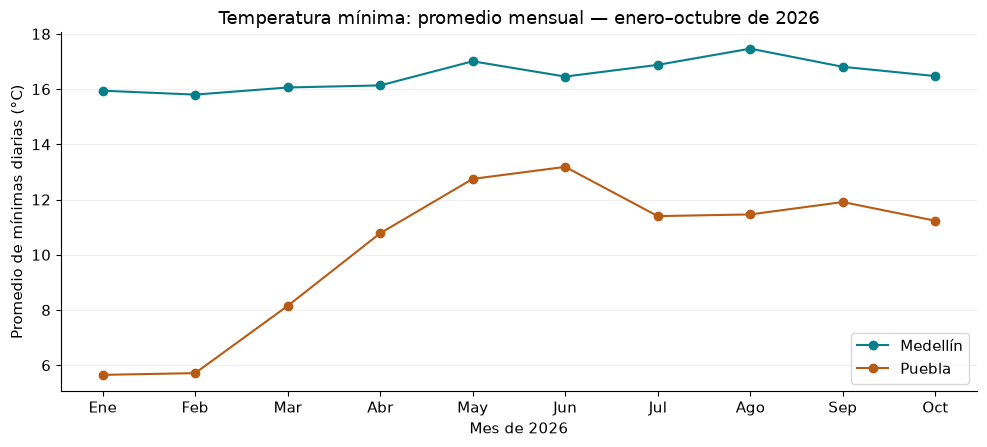

In [8]:
mes_diario = fechas.astype('datetime64[M]')
meses = np.unique(mes_diario)
etiquetas_meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct']
t_mensual = np.array([temperatura[(mes_diario == m) & validas_t].mean(axis=0) for m in meses])
p_mensual = np.array([lluvia[(mes_diario == m) & validas_p].sum(axis=0) for m in meses])
assert np.allclose(p_mensual.sum(axis=0), lluvia.sum(axis=0))
tabla_html(['Mes 2026', 'Días', 'Mínima media Medellín (°C)', 'Mínima media Puebla (°C)',
            'Lluvia Medellín (mm)', 'Lluvia Puebla (mm)'],
           [[str(m), int((mes_diario == m).sum()), *np.round(t_mensual[i], 2),
             *np.round(p_mensual[i], 2)] for i, m in enumerate(meses)])
plt.rcParams.update({'figure.figsize': (10, 4.6), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
colores = ['#087E8B', '#B85B15']
fig, ax = plt.subplots()
for j, ciudad in enumerate(ciudades):
    ax.plot(etiquetas_meses, t_mensual[:, j], marker='o', color=colores[j], label=ciudad)
ax.set(title='Temperatura mínima: promedio mensual — enero–octubre de 2026',
       xlabel='Mes de 2026', ylabel='Promedio de mínimas diarias (°C)')
ax.grid(axis='y', alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

**Lectura de la gráfica 1.** Medellín tiene una mínima media del periodo de 16.51 °C y Puebla de 10.25 °C. La menor media mensual ocurre en Feb para Medellín (15.80 °C) y en Ene para Puebla (5.65 °C). **No permite concluir** cómo fueron las máximas diarias ni que exista una tendencia climática de largo plazo.

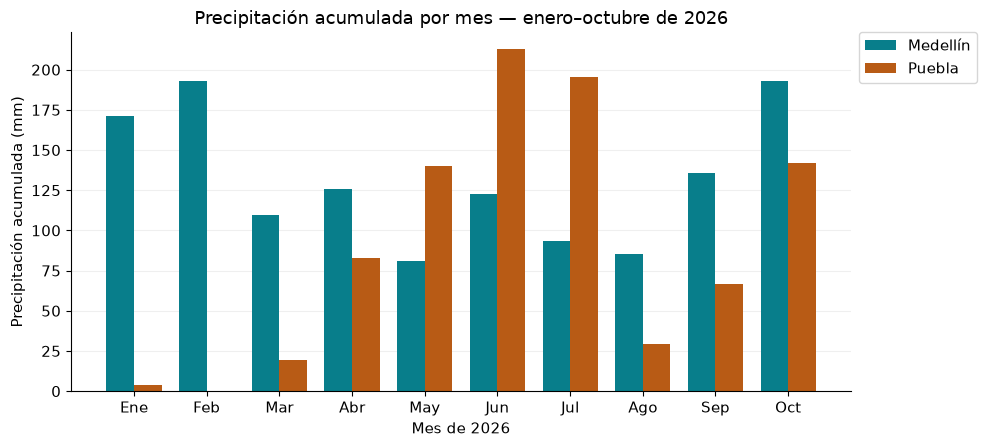

In [9]:
x = np.arange(len(meses))
fig, ax = plt.subplots()
ancho = 0.38
for j, ciudad in enumerate(ciudades):
    ax.bar(x + (j - 0.5) * ancho, p_mensual[:, j], width=ancho,
           color=colores[j], label=ciudad)
ax.set_xticks(x, etiquetas_meses)
ax.set(title='Precipitación acumulada por mes — enero–octubre de 2026',
       xlabel='Mes de 2026', ylabel='Precipitación acumulada (mm)')
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), borderaxespad=0)
fig.tight_layout()
plt.show()

**Lectura de la gráfica 2.** El mayor acumulado mensual de Medellín es 193.00 mm en Feb; el de Puebla es 212.60 mm en Jun. Mayo–octubre reúne el 54.3% y el 88.1% de la lluvia del periodo, respectivamente. **No permite concluir** que llovió todos los días de esos meses ni que esos acumulados se repitan cada año.

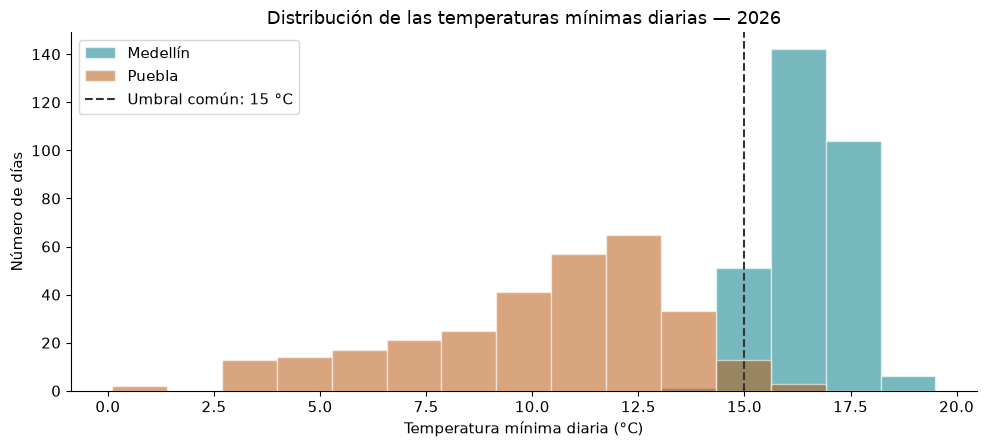

In [10]:
# Bordes idénticos para comparar las distribuciones sin cambiar de escala.
bordes = np.linspace(temperatura[validas_t].min() - 0.5,
                     temperatura[validas_t].max() + 0.5, 16)
fig, ax = plt.subplots()
for j, ciudad in enumerate(ciudades):
    ax.hist(temperatura[validas_t, j], bins=bordes, color=colores[j],
            alpha=0.55, label=ciudad, edgecolor='white')
ax.axvline(UMBRAL_T, color='#333333', linestyle='--', label='Umbral común: 15 °C')
ax.set(title='Distribución de las temperaturas mínimas diarias — 2026',
       xlabel='Temperatura mínima diaria (°C)', ylabel='Número de días')
ax.legend()
fig.tight_layout()
plt.show()

**Lectura de la gráfica 3.** La desviación estándar de las mínimas es 0.90 °C en Medellín y 3.09 °C en Puebla. El umbral común de 15 °C se supera en 284 y 5 días, respectivamente. El histograma **no permite concluir** en qué orden ocurrieron esos días, ni atribuir las diferencias a una causa.

## E. Interpretación y respuesta a la pregunta guía
Los hallazgos siguientes se refieren exclusivamente a las estaciones elegidas y a enero–octubre de 2026. Se distingue la diferencia térmica de la similitud de presencia de lluvia; ambas se respaldan con los mismos días observados. Los porcentajes de mayo–octubre describen este periodo, no establecen por sí solos una temporada típica de largo plazo.

1. **Diferencia térmica:** la mínima media es 16.51 °C en Medellín y 10.25 °C en Puebla; la diferencia Medellín − Puebla es 6.26 °C. Medellín tiene el promedio mayor y Medellín la menor variabilidad diaria. La expectativa térmica inicial se sostiene en estos datos.

2. **Similitud:** ambas estaciones registran días con lluvia: 138 de 304 en Medellín y 96 de 304 en Puebla; en 39 fechas ambas reportan más de 0 mm. Esto solo indica coincidencia de registros diarios; no prueba que se trate del mismo fenómeno meteorológico.

3. **Diferencia en acumulados:** Medellín registra 1310.40 mm y Puebla 892.50 mm, una diferencia de 417.90 mm. Los días con al menos 1 mm son 117 y 77, respectivamente; este conteo evita interpretar todas las cantidades muy pequeñas como episodios de igual importancia.

### Alcance y limitaciones
El calendario común evita comparar meses distintos. Quedan **304 observaciones por ciudad y por variable**, sin faltantes ni fechas duplicadas; por eso no fue necesario eliminar fechas en las comparaciones diarias. Se seleccionó temperatura mínima porque la máxima de LA ALDEA tenía dos ausencias; no se sustituyeron por cero ni se interpolaron. Los archivos de respaldo y los estados de aprobación permiten revisar esa elección.

Los datos del IDEAM están En revisión o Preliminar, y el TXT de CONAGUA no informa un estado de aprobación individual. LA ALDEA y el observatorio de Puebla representan puntos de observación; las diferencias de altitud y entorno pueden influir, pero este análisis no aísla sus efectos. Los periodos diarios se conservan con las fechas de cada fuente y sus ventanas horarias pueden diferir. Los resultados no representan toda la ciudad, no prueban causalidad y no permiten describir un año completo ni cambio climático: faltan noviembre y diciembre de 2026.

### Revisión de la entrega
- Dos ciudades de países diferentes: Medellín, Colombia, y Puebla, México.
- Mismo periodo: 2026-01-01 a 2026-10-31; frecuencia diaria; °C y mm.
- Fuentes, columnas, unidades, estados de aprobación y decisiones documentados.
- Carga desde `datos/`, tipos, dimensiones, faltantes y duplicados revisados.
- NumPy: arrays, cortes, máscaras booleanas, estadísticas y broadcasting.
- Tres gráficas con títulos, ejes, unidades, leyendas y lecturas con límites.
- Hallazgos con evidencia y notebook ejecutado en orden dentro de EA3.

**Reproducir:** seleccionar un kernel Python con NumPy y Matplotlib (`pip install -r requirements.txt`, desde esta carpeta) y ejecutar todas las celdas en orden. Los datos ya están incluidos, por lo que no se necesita descargarlos ni modificar AE1 o AE2. Los scripts de descarga y construcción son auxiliares: la explicación completa está en este notebook.